<a href="https://colab.research.google.com/github/HajerBouaziz/assistant-cluster-ia/blob/main/Hajer_Speech_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q lightning torchmetrics scikit-learn plotly ipywidgets pnpl

base_path = "./libribrain"
try:
    import google.colab
    in_colab = True
    base_path = "/content"
except ImportError:
    in_colab = False

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
import torch, pnpl
print("torch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Carte :", torch.cuda.get_device_name(0))
print("base_path :", base_path)

torch : 2.11.0+cu130
GPU disponible : True
Carte : Tesla T4
base_path : /content


In [ ]:
from pnpl.datasets import LibriBrainSpeech
from torch.utils.data import DataLoader

example_data = LibriBrainSpeech(
    data_path=f"{base_path}/data/",
    include_run_keys=[("0", "1", "Sherlock1", "1")],
    tmin=0.0,
    tmax=0.8,
    preload_files=True,
)

num_workers = 2 if in_colab else 0
example_loader = DataLoader(example_data, batch_size=32, shuffle=True, num_workers=num_workers)

print("Number of samples:", len(example_data))

(…)-0_ses-1_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  342MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

Done!
Number of samples: 1373


In [ ]:
x, y = example_data[0]
print("x :", x.shape, x.dtype)
print("y :", y.shape, y.dtype)
print("proportion de parole dans cet exemple :", float(y.float().mean()))

x : torch.Size([306, 200]) torch.float32
y : torch.Size([200]) torch.int32
proportion de parole dans cet exemple : 0.0


In [ ]:
import torch
props = torch.stack([example_data[i][1].float().mean() for i in range(len(example_data))])
print("proportion moyenne de parole :", float(props.mean()))
print("fenêtres 100 % silence :", int((props == 0).sum()), "sur", len(props))
print("fenêtres 100 % parole  :", int((props == 1).sum()), "sur", len(props))

proportion moyenne de parole : 0.7693408727645874
fenêtres 100 % silence : 65 sur 1373
fenêtres 100 % parole  : 688 sur 1373


In [ ]:
import h5py, numpy as np
hdf5_file_path = f"{base_path}/data/Sherlock1/derivatives/serialised/sub-0_ses-1_task-Sherlock1_run-1_proc-bads+headpos+sss+notch+bp+ds_meg.h5"

with h5py.File(hdf5_file_path, "r") as f:
    for key in f.keys():
        print(key, f[key].shape, f[key].dtype)
    data = f["data"][:]
    times = f["times"][:]

print("durée (s) :", times[-1])
print("pas de temps :", times[1] - times[0])
print("min / max :", data.min(), data.max())
print("moyenne / écart-type :", data.mean(), data.std())

data (306, 278000) float32
times (278000,) float32
durée (s) : 1111.996
pas de temps : 0.004
min / max : -5.500717e-09 3.0759975e-09
moyenne / écart-type : -2.1236126e-14 2.2824869e-11


In [ ]:
import pandas as pd
tsv_file_path = f"{base_path}/data/Sherlock1/derivatives/events/sub-0_ses-1_task-Sherlock1_run-1_events.tsv"
tsv = pd.read_csv(tsv_file_path, sep="\t")
print(tsv.shape)
print(tsv.dtypes)
print(tsv["kind"].value_counts())
print(tsv.head(20))

(12806, 12)
idx               int64
wavile           object
kind             object
segment          object
sentenceidx     float64
wordidx         float64
phonemeidx      float64
timemeg         float64
timeds          float64
timechapter     float64
timesentence    float64
duration        float64
dtype: object
kind
phoneme    9592
word       2836
silence     378
Name: count, dtype: int64
    idx     wavile     kind  segment  sentenceidx  wordidx  phonemeidx  \
0     1  segments/  silence      NaN          NaN      NaN         NaN   
1     2  segments/     word        A          0.0      0.0         NaN   
2     3  segments/  phoneme     ah_S          0.0      0.0         0.0   
3     4  segments/     word    Study          0.0      1.0         NaN   
4     5  segments/  phoneme      s_B          0.0      1.0         0.0   
5     6  segments/  phoneme      t_I          0.0      1.0         1.0   
6     7  segments/  phoneme     ah_I          0.0      1.0         2.0   
7     8  segmen

In [ ]:
sil = tsv[tsv["kind"] == "silence"]
print("durée totale de silence (s) :", sil["duration"].sum())
print(sil["duration"].describe())

ph = tsv[tsv["kind"] == "phoneme"].copy()
ph["base"] = ph["segment"].str.split("_").str[0]
print("\nphonèmes distincts sans suffixe :", ph["base"].nunique())
print("suffixes :", ph["segment"].str.split("_").str[1].value_counts().to_dict())
print(ph["duration"].describe())
print(ph["base"].value_counts().head(10))

durée totale de silence (s) : 224.885
count    378.000000
mean       0.594934
std        0.323163
min        0.115000
25%        0.350000
50%        0.525500
75%        0.768000
max        2.616000
Name: duration, dtype: float64

phonèmes distincts sans suffixe : 40
suffixes : {'I': 4209, 'B': 2547, 'E': 2547, 'S': 289}
count    9592.000000
mean        0.081294
std         0.061154
min         0.010000
25%         0.050000
50%         0.070000
75%         0.090000
max         1.170000
Name: duration, dtype: float64
base
ah    943
t     687
n     686
ih    641
d     500
s     448
r     365
m     342
l     340
iy    340
Name: count, dtype: int64


In [ ]:
base_counts = ph["base"].value_counts()
print(base_counts.to_string())

arpabet39 = set("aa ae ah ao aw ay b ch d dh eh er ey f g hh ih iy jh k l m n ng ow oy p r s sh t th uh uw v w y z zh".split())
print("\nhors liste des 39 :", set(base_counts.index) - arpabet39)
print("manquants         :", arpabet39 - set(base_counts.index))

print(ph.sort_values("duration", ascending=False).head(5)[["segment", "timemeg", "duration"]])

base
ah     943
t      687
n      686
ih     641
d      500
s      448
r      365
m      342
l      340
iy     340
ae     311
z      288
eh     268
k      259
er     251
ay     250
hh     225
dh     223
w      201
v      176
b      171
p      169
f      161
uw     157
ao     132
ey     126
ow     125
aa     121
ng     107
y       87
g       84
oov     83
th      68
aw      64
sh      60
ch      48
uh      41
jh      30
oy      10
zh       4

hors liste des 39 : {'oov'}
manquants         : set()
     segment  timemeg  duration
454    oov_S   70.506      1.17
5981   oov_S  526.954      1.02
3463   oov_S  318.642      0.87
3249   oov_S  300.794      0.86
1873   oov_S  188.226      0.84


In [ ]:
from pnpl.datasets import LibriBrainSpeech
from torch.utils.data import DataLoader
import psutil

num_workers = 2 if in_colab else 0
D = f"{base_path}/data/"
kw = dict(standardize=True, tmin=0.0, tmax=0.8, preload_files=True)

train_run_keys = [("0", str(i), "Sherlock1", "1") for i in range(1, 4)]
train_data = LibriBrainSpeech(data_path=D, include_run_keys=train_run_keys, **kw)
val_data   = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "11", "Sherlock1", "2")], **kw)
test_data  = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "12", "Sherlock1", "2")], **kw)

print("train :", len(train_data), "| val :", len(val_data), "| test :", len(test_data))
print("RAM utilisée : %.1f / %.1f Go" % (psutil.virtual_memory().used/1e9, psutil.virtual_memory().total/1e9))

# Contrôle de la standardisation (attendu : écart-type proche de 1)
for name, ds in [("train", train_data), ("val", val_data), ("test", test_data)]:
    x, _ = ds[0]
    print(name, "| moyenne : %.3e | écart-type : %.3e" % (x.mean(), x.std()))

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  461MB            

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  429MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

(…)-0_ses-3_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.53M [00:00<?, ?B/s]

(…)-0_ses-2_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.46M [00:00<?, ?B/s]

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  440MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

(…)0_ses-12_task-Sherlock1_run-2_events.tsv:   0%|          | 0.00/1.41M [00:00<?, ?B/s]

Done!
train : 4946 | val : 1671 | test : 1772
RAM utilisée : 2.1 / 13.6 Go
train | moyenne : 7.404e-03 | écart-type : 1.355e-01
val | moyenne : -3.478e-02 | écart-type : 8.408e-01
test | moyenne : -4.032e-01 | écart-type : 9.474e+00


In [ ]:
import numpy as np
rng = np.random.default_rng(42)

for name, ds in [("train", train_data), ("val", val_data), ("test", test_data)]:
    idx = rng.choice(len(ds), size=300, replace=False)
    stds = np.array([float(ds[i][0].std()) for i in idx])
    maxs = np.array([float(ds[i][0].abs().max()) for i in idx])
    print(f"{name:5s} | écart-type par fenêtre : médiane {np.median(stds):.2f} "
          f"(5e–95e percentile : {np.percentile(stds,5):.2f}–{np.percentile(stds,95):.2f})"
          f" | valeur max absolue médiane {np.median(maxs):.1f}, max {maxs.max():.1f}")

train | écart-type par fenêtre : médiane 0.12 (5e–95e percentile : 0.09–0.17) | valeur max absolue médiane 2.3, max 6.6
val   | écart-type par fenêtre : médiane 0.52 (5e–95e percentile : 0.44–0.71) | valeur max absolue médiane 4.8, max 10.0
test  | écart-type par fenêtre : médiane 0.48 (5e–95e percentile : 0.41–0.66) | valeur max absolue médiane 4.2, max 10.0


In [ ]:
import inspect
from pnpl.datasets import LibriBrainSpeech
print(inspect.signature(LibriBrainSpeech.__init__))
print([a for a in dir(train_data) if any(k in a.lower() for k in ("mean", "std", "clip", "standard"))])

(self, data_path: str, partition: Optional[str] = None, preprocessing_str: str = 'bads+headpos+sss+notch+bp+ds', tmin: float = 0.0, tmax: float = 0.5, include_run_keys: list = None, exclude_run_keys: list = None, exclude_tasks: list = None, standardize: bool = True, clipping_boundary: Optional[float] = 10.0, channel_means: Optional[numpy.ndarray] = None, channel_stds: Optional[numpy.ndarray] = None, include_info: bool = False, oversample_silence_jitter: int = 0, preload_files: bool = True, stride: Optional[int] = None, download: bool = True, preload_h5: bool = False)
['_accumulate_stds', '_calculate_standardization_params', 'broadcasted_means', 'broadcasted_stds', 'calculate_standardization_params', 'channel_means', 'channel_stds', 'clip_sample', 'clipping_boundary', 'setup_standardization', 'standardize', 'standardize_enabled']


In [ ]:
cm, cs = train_data.channel_means, train_data.channel_stds
print("channel_means :", type(cm), getattr(cm, "shape", None), "| channel_stds :", getattr(cs, "shape", None))

kw2 = dict(standardize=True, tmin=0.0, tmax=0.8, preload_files=True, channel_means=cm, channel_stds=cs)
val_data  = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "11", "Sherlock1", "2")], **kw2)
test_data = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "12", "Sherlock1", "2")], **kw2)

import numpy as np
rng = np.random.default_rng(42)
for name, ds in [("train", train_data), ("val", val_data), ("test", test_data)]:
    idx = rng.choice(len(ds), size=300, replace=False)
    stds = np.array([float(ds[i][0].std()) for i in idx])
    print(f"{name:5s} | écart-type par fenêtre : médiane {np.median(stds):.2f}")

channel_means : <class 'numpy.ndarray'> (306,) | channel_stds : (306,)
train | écart-type par fenêtre : médiane 0.12
val   | écart-type par fenêtre : médiane 0.12
test  | écart-type par fenêtre : médiane 0.12


In [ ]:
import random
import torch
from torch.utils.data import DataLoader

random.seed(42)

# Les 23 capteurs identifiés comme utiles pour la détection de parole
SENSORS_SPEECH_MASK = [18, 20, 22, 23, 45, 120, 138, 140, 142, 143, 145,
                       146, 147, 149, 175, 176, 177, 179, 180, 198, 271, 272, 275]

class FilteredDataset(torch.utils.data.Dataset):
    """
    dataset : jeu LibriBrainSpeech
    limit_samples : limite optionnelle du nombre d'échantillons
    apply_sensors_speech_mask : si True, ne garde que les 23 capteurs
    Retourne (signal des capteurs, étiquette du milieu de la fenêtre).
    """
    def __init__(self, dataset, limit_samples=None, apply_sensors_speech_mask=True):
        self.dataset = dataset
        self.limit_samples = limit_samples
        self.apply_sensors_speech_mask = apply_sensors_speech_mask
        self.sensors_speech_mask = SENSORS_SPEECH_MASK
        self.balanced_indices = random.sample(range(len(dataset.samples)), len(dataset.samples))

    def __len__(self):
        if self.limit_samples is not None:
            return self.limit_samples
        return len(self.balanced_indices)

    def __getitem__(self, index):
        original_idx = self.balanced_indices[index]
        x, y = self.dataset[original_idx]
        if self.apply_sensors_speech_mask:
            x = x[self.sensors_speech_mask]
        return [x, y[y.shape[0] // 2]]


num_workers = 2 if in_colab else 0

print("Filtered dataset:")
train_data_filtered = FilteredDataset(train_data)
train_loader_filtered = DataLoader(train_data_filtered, batch_size=32, shuffle=True, num_workers=num_workers)
print(f"Train data contains {len(train_data_filtered)} samples")

val_data_filtered = FilteredDataset(val_data)
val_loader_filtered = DataLoader(val_data_filtered, batch_size=32, shuffle=False, num_workers=num_workers)
print(f"Validation data contains {len(val_data_filtered)} samples")

test_data_filtered = FilteredDataset(test_data)
test_loader_filtered = DataLoader(test_data_filtered, batch_size=32, shuffle=False, num_workers=num_workers)
print(f"Test data contains {len(test_data_filtered)} samples\n")

inputs, labels = next(iter(train_loader_filtered))
print("Batch input shape:", inputs.shape)
print("Batch label shape:", labels.shape)
print("Étiquettes du batch :", labels.tolist())

Filtered dataset:
Train data contains 4946 samples
Validation data contains 1671 samples
Test data contains 1772 samples

Batch input shape: torch.Size([32, 23, 200])
Batch label shape: torch.Size([32])
Étiquettes du batch : [1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [ ]:
import torch, numpy as np
from sklearn.metrics import f1_score

def all_labels(loader):
    return torch.cat([y for _, y in loader]).numpy().astype(int)

y_train, y_val, y_test = (all_labels(l) for l in
                          (train_loader_filtered, val_loader_filtered, test_loader_filtered))

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} | {len(y)} fenêtres | proportion de parole : {y.mean():.3f}")

# Modèles naïfs sur la validation
for name, pred in [("tout 'parole'", np.ones_like(y_val)), ("tout 'silence'", np.zeros_like(y_val))]:
    print(f"F1-macro val, {name:15s}: {f1_score(y_val, pred, average='macro', zero_division=0):.4f}")

train | 4946 fenêtres | proportion de parole : 0.774
val   | 1671 fenêtres | proportion de parole : 0.743
test  | 1772 fenêtres | proportion de parole : 0.748
F1-macro val, tout 'parole'  : 0.4262
F1-macro val, tout 'silence' : 0.2047


In [ ]:
import torch, torch.nn as nn, numpy as np, copy
from sklearn.metrics import f1_score

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

class SpeechDetector(nn.Module):
    def __init__(self, n_sensors=23, hidden=100, dropout=0.5):
        super().__init__()
        self.conv = nn.Conv1d(n_sensors, hidden, kernel_size=3)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(hidden, hidden, num_layers=2, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        h = self.drop(torch.relu(self.conv(x)))          # (B, hidden, T')
        out, _ = self.lstm(h.transpose(1, 2))             # (B, T', hidden)
        return self.fc(self.drop(out[:, -1])).squeeze(-1) # logit (B,)

model = SpeechDetector().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
bce = nn.BCEWithLogitsLoss()
LS = 0.1

def evaluate(loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(torch.sigmoid(model(x.to(device))).cpu()); ys.append(y)
    y = torch.cat(ys).numpy().astype(int); p = torch.cat(ps).numpy()
    return y, p, f1_score(y, (p > 0.5).astype(int), average="macro", zero_division=0)

best_f1, best_state, wait = -1, None, 0
for epoch in range(1, 16):
    model.train(); tot = 0
    for x, y in train_loader_filtered:
        x, y = x.to(device), y.float().to(device)
        loss = bce(model(x), y * (1 - LS) + 0.5 * LS)     # label smoothing
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(y)
    _, _, f1 = evaluate(val_loader_filtered)
    print(f"époque {epoch:2d} | perte train {tot/len(train_data_filtered):.4f} | F1-macro val {f1:.4f}")
    if f1 > best_f1: best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= 10: print("arrêt anticipé"); break

model.load_state_dict(best_state)
_, _, f1_val = evaluate(val_loader_filtered)
_, _, f1_test = evaluate(test_loader_filtered)
print(f"\nMeilleur modèle | F1-macro val : {f1_val:.4f} | test : {f1_test:.4f}  (plancher naïf val : 0.4262)")

époque  1 | perte train 0.5739 | F1-macro val 0.4333
époque  2 | perte train 0.5582 | F1-macro val 0.4262
époque  3 | perte train 0.5651 | F1-macro val 0.4449
époque  4 | perte train 0.5662 | F1-macro val 0.4647
époque  5 | perte train 0.5594 | F1-macro val 0.4262
époque  6 | perte train 0.5682 | F1-macro val 0.4262
époque  7 | perte train 0.5586 | F1-macro val 0.4262
époque  8 | perte train 0.5461 | F1-macro val 0.4262
époque  9 | perte train 0.5575 | F1-macro val 0.4262
époque 10 | perte train 0.5500 | F1-macro val 0.4262
époque 11 | perte train 0.5400 | F1-macro val 0.4262
époque 12 | perte train 0.5379 | F1-macro val 0.6150
époque 13 | perte train 0.5396 | F1-macro val 0.4262
époque 14 | perte train 0.5339 | F1-macro val 0.4262
époque 15 | perte train 0.5219 | F1-macro val 0.6072

Meilleur modèle | F1-macro val : 0.6150 | test : 0.6264  (plancher naïf val : 0.4262)


F1-macro test : 0.6264 | AUC : 0.7376
              precision    recall  f1-score   support

     silence      0.539     0.322     0.403       447
      parole      0.799     0.907     0.849      1325

    accuracy                          0.760      1772
   macro avg      0.669     0.615     0.626      1772
weighted avg      0.733     0.760     0.737      1772



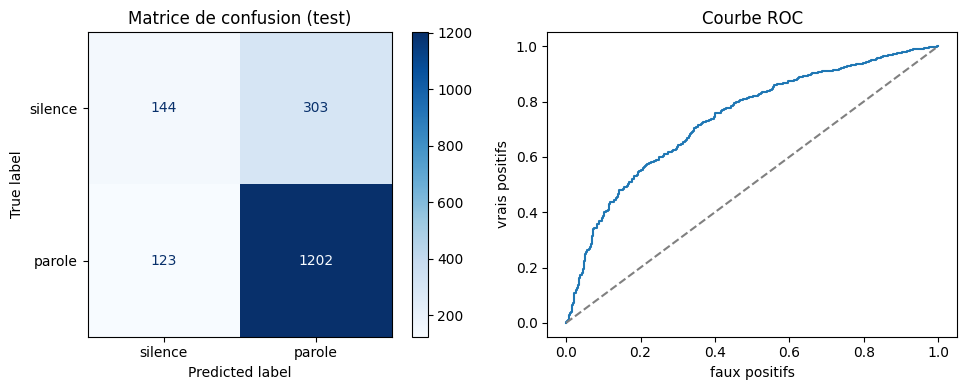

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report
import matplotlib.pyplot as plt

y_te, p_te, f1 = evaluate(test_loader_filtered)
y_pred = (p_te > 0.5).astype(int)

print(f"F1-macro test : {f1:.4f} | AUC : {roc_auc_score(y_te, p_te):.4f}")
print(classification_report(y_te, y_pred, target_names=["silence", "parole"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=["silence", "parole"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("Matrice de confusion (test)")
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title("Courbe ROC"); ax[1].set_xlabel("faux positifs"); ax[1].set_ylabel("vrais positifs")
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

y_va, p_va, _ = evaluate(val_loader_filtered)
seuils = np.arange(0.30, 0.95, 0.01)
f1s = [f1_score(y_va, (p_va > s).astype(int), average="macro", zero_division=0) for s in seuils]
s_opt = seuils[int(np.argmax(f1s))]
print(f"Seuil optimal sur la validation : {s_opt:.2f} (F1-macro val {max(f1s):.4f}, contre {f1s[int(np.argmin(abs(seuils-0.5)))]:.4f} à 0,50)")

y_te, p_te, _ = evaluate(test_loader_filtered)
for s in (0.5, s_opt):
    print(f"seuil {s:.2f} -> F1-macro test {f1_score(y_te, (p_te > s).astype(int), average='macro', zero_division=0):.4f}")

Seuil optimal sur la validation : 0.62 (F1-macro val 0.6486, contre 0.6150 à 0,50)
seuil 0.50 -> F1-macro test 0.6264
seuil 0.62 -> F1-macro test 0.6587


In [ ]:
import time, gc, random, psutil, numpy as np, pandas as pd, torch, torch.nn as nn, copy
from sklearn.metrics import f1_score
from pnpl.datasets import LibriBrainSpeech
from torch.utils.data import DataLoader

def evaluate(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(torch.sigmoid(model(x.to(device))).cpu()); ys.append(y)
    y = torch.cat(ys).numpy().astype(int); p = torch.cat(ps).numpy()
    return y, p, f1_score(y, (p > 0.5).astype(int), average="macro", zero_division=0)

preds = {}
def run_experiment(n_sessions, seed=42, epochs=15, patience=10):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    D = f"{base_path}/data/"
    kw = dict(standardize=True, tmin=0.0, tmax=0.8, preload_files=True)
    t0 = time.time()
    keys = [("0", str(i), "Sherlock1", "1") for i in range(1, n_sessions + 1)]
    tr = LibriBrainSpeech(data_path=D, include_run_keys=keys, **kw)
    kw2 = dict(kw, channel_means=tr.channel_means, channel_stds=tr.channel_stds)
    va = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "11", "Sherlock1", "2")], **kw2)
    te = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "12", "Sherlock1", "2")], **kw2)
    tr_f, va_f, te_f = FilteredDataset(tr), FilteredDataset(va), FilteredDataset(te)
    tl = DataLoader(tr_f, batch_size=32, shuffle=True, num_workers=num_workers)
    vl = DataLoader(va_f, batch_size=32, shuffle=False, num_workers=num_workers)
    sl = DataLoader(te_f, batch_size=32, shuffle=False, num_workers=num_workers)
    t_data = time.time() - t0

    model = SpeechDetector().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    bce, LS = nn.BCEWithLogitsLoss(), 0.1
    best_f1, best_state, wait, t1 = -1, None, 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in tl:
            x, y = x.to(device), y.float().to(device)
            loss = bce(model(x), y * (1 - LS) + 0.5 * LS)
            opt.zero_grad(); loss.backward(); opt.step()
        _, _, f1 = evaluate(model, vl)
        print(f"[{n_sessions} sessions] époque {epoch:2d} | F1-macro val {f1:.4f}")
        if f1 > best_f1: best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    t_train = time.time() - t1
    model.load_state_dict(best_state)
    _, _, f1_val = evaluate(model, vl)
    y_te, p_te, f1_te = evaluate(model, sl)
    preds[n_sessions] = (y_te, p_te)
    row = dict(n_sessions=n_sessions, seed=seed, n_train_windows=len(tr_f),
               f1_val=round(f1_val, 4), f1_test=round(f1_te, 4),
               temps_donnees_s=round(t_data), temps_entrainement_s=round(t_train),
               ram_go=round(psutil.virtual_memory().used / 1e9, 1))
    del tr, va, te, tr_f, va_f, te_f, tl, vl, sl, model; gc.collect(); torch.cuda.empty_cache()
    return row

results = []
for n in [3, 6, 10]:
    results.append(run_experiment(n))
    pd.DataFrame(results).to_csv("results.csv", index=False)
    print(pd.DataFrame(results))

[3 sessions] époque  1 | F1-macro val 0.4333
[3 sessions] époque  2 | F1-macro val 0.4262
[3 sessions] époque  3 | F1-macro val 0.4262
[3 sessions] époque  4 | F1-macro val 0.4430
[3 sessions] époque  5 | F1-macro val 0.4262
[3 sessions] époque  6 | F1-macro val 0.4262
[3 sessions] époque  7 | F1-macro val 0.4262
[3 sessions] époque  8 | F1-macro val 0.4716
[3 sessions] époque  9 | F1-macro val 0.4262
[3 sessions] époque 10 | F1-macro val 0.6483
[3 sessions] époque 11 | F1-macro val 0.6160
[3 sessions] époque 12 | F1-macro val 0.5371
[3 sessions] époque 13 | F1-macro val 0.6473
[3 sessions] époque 14 | F1-macro val 0.6409
[3 sessions] époque 15 | F1-macro val 0.5629
   n_sessions  seed  n_train_windows  f1_val  f1_test  temps_donnees_s  \
0           3    42             4946  0.6483   0.6748                3   

   temps_entrainement_s  ram_go  
0                    81     2.8  


(…)-0_ses-4_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

(…)-0_ses-5_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/956k [00:00<?, ?B/s]

(…)-0_ses-6_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.24M [00:00<?, ?B/s]

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  305MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

... (14 outputs left out)

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

(…)0_ses-10_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/708k [00:00<?, ?B/s]

(…)-0_ses-8_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.43M [00:00<?, ?B/s]

Done!
[10 sessions] époque  1 | F1-macro val 0.4262
[10 sessions] époque  2 | F1-macro val 0.5573
[10 sessions] époque  3 | F1-macro val 0.4406
[10 sessions] époque  4 | F1-macro val 0.5403
[10 sessions] époque  5 | F1-macro val 0.4262
[10 sessions] époque  6 | F1-macro val 0.5680
[10 sessions] époque  7 | F1-macro val 0.6245
[10 sessions] époque  8 | F1-macro val 0.6626
[10 sessions] époque  9 | F1-macro val 0.6533
[10 sessions] époque 10 | F1-macro val 0.6689
[10 sessions] époque 11 | F1-macro val 0.6698
[10 sessions] époque 12 | F1-macro val 0.6590
[10 sessions] époque 13 | F1-macro val 0.6629
[10 sessions] époque 14 | F1-macro val 0.6278
[10 sessions] époque 15 | F1-macro val 0.4590
   n_sessions  seed  n_train_windows  f1_val  f1_test  temps_donnees_s  \
0           3    42             4946  0.6483   0.6748                3   
1           6    42             8961  0.6635   0.6688               13   
2          10    42            14681  0.6698   0.6910               28   

   temp

In [ ]:
!du -sh /content/data ~/.cache/huggingface

4.3G	/content/data
320K	/root/.cache/huggingface


In [ ]:
import time, gc, random, psutil, numpy as np, pandas as pd, torch, torch.nn as nn, copy
from sklearn.metrics import f1_score
from pnpl.datasets import LibriBrainSpeech
from torch.utils.data import DataLoader

def evaluate(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(torch.sigmoid(model(x.to(device))).cpu()); ys.append(y)
    y = torch.cat(ys).numpy().astype(int); p = torch.cat(ps).numpy()
    return y, p, f1_score(y, (p > 0.5).astype(int), average="macro", zero_division=0)

preds = {}
def run_experiment(n_sessions, seed=42, epochs=15, patience=10, keys=None):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    D = f"{base_path}/data/"
    kw = dict(standardize=True, tmin=0.0, tmax=0.8, preload_files=True)
    t0 = time.time()
    keys = keys or [("0", str(i), "Sherlock1", "1") for i in range(1, n_sessions + 1)]
    tr = LibriBrainSpeech(data_path=D, include_run_keys=keys, **kw)
    kw2 = dict(kw, channel_means=tr.channel_means, channel_stds=tr.channel_stds)
    va = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "11", "Sherlock1", "2")], **kw2)
    te = LibriBrainSpeech(data_path=D, include_run_keys=[("0", "12", "Sherlock1", "2")], **kw2)
    tr_f, va_f, te_f = FilteredDataset(tr), FilteredDataset(va), FilteredDataset(te)
    tl = DataLoader(tr_f, batch_size=32, shuffle=True, num_workers=num_workers)
    vl = DataLoader(va_f, batch_size=32, shuffle=False, num_workers=num_workers)
    sl = DataLoader(te_f, batch_size=32, shuffle=False, num_workers=num_workers)
    t_data = time.time() - t0

    model = SpeechDetector().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    bce, LS = nn.BCEWithLogitsLoss(), 0.1
    best_f1, best_state, wait, t1 = -1, None, 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in tl:
            x, y = x.to(device), y.float().to(device)
            loss = bce(model(x), y * (1 - LS) + 0.5 * LS)
            opt.zero_grad(); loss.backward(); opt.step()
        _, _, f1 = evaluate(model, vl)
        if f1 > best_f1: best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    t_train = time.time() - t1
    model.load_state_dict(best_state)

    y_va, p_va, f1_val = evaluate(model, vl)
    seuils = np.arange(0.30, 0.95, 0.01)
    f1s = [f1_score(y_va, (p_va > s).astype(int), average="macro", zero_division=0) for s in seuils]
    s_opt = float(seuils[int(np.argmax(f1s))])
    y_te, p_te, f1_te = evaluate(model, sl)
    f1_te_opt = f1_score(y_te, (p_te > s_opt).astype(int), average="macro", zero_division=0)
    preds[(n_sessions, seed)] = (y_te, p_te)

    row = dict(n_sessions=n_sessions, seed=seed, n_train_windows=len(tr_f),
               f1_val=round(f1_val, 4), f1_test=round(f1_te, 4),
               seuil=round(s_opt, 2), f1_test_seuil=round(f1_te_opt, 4),
               temps_donnees_s=round(t_data), temps_entrainement_s=round(t_train),
               ram_go=round(psutil.virtual_memory().used / 1e9, 1))
    del tr, va, te, tr_f, va_f, te_f, tl, vl, sl, model; gc.collect(); torch.cuda.empty_cache()
    return row

# Configuration du notebook officiel : Sherlock1 (sessions 1-10) + Sherlock2 (sessions 1-12 sauf 2)
keys_officiel = ([("0", str(i), "Sherlock1", "1") for i in range(1, 11)]
               + [("0", str(i), "Sherlock2", "1") for i in range(1, 13) if i != 2])

res21 = []
for seed in [42, 43, 44]:
    res21.append(run_experiment(len(keys_officiel), seed=seed, keys=keys_officiel))
    pd.DataFrame(res21).to_csv("results_21.csv", index=False)
    print(res21[-1])

df21 = pd.DataFrame(res21)
print(df21[["f1_val", "f1_test", "f1_test_seuil"]].agg(["mean", "std"]).round(4))

ModuleNotFoundError: No module named 'pnpl'